# Exploring Forty Years of Weather Across Contrasting Environments

### Introduction

The objective of this project is to investigate how weather conditions have evolved over the last 40 years (1986–2025) across different geographical and climatic environments.

Using historical daily weather data retrieved from the Open-Meteo API, I selected ten locations representing the five major Köppen–Geiger climate groups:

| Climate Group | Climate Type | Selected Locations |
|---|---|---|
| A | Tropical | Kisangani, Darwin |
| B | Dry | Aswan, Ulaanbaatar |
| C | Temperate | Tunis, Milan |
| D | Continental | Moscow, Yellowknife |
| E | Polar | Longyearbyen, South Pole |

I selected two contrasting locations within each group to explore whether places sharing a broad climate classification also show similar temperature trends.

The analysis focuses on three questions:

1. How have annual mean temperatures evolved between 1986 and 2025?
2. How do annual temperature anomalies compare with the 1986–2005 reference period?
3. Do locations within the same climate group experience similar warming rates?

   &Additional analysis (open horizon)  How are humidity and apparent temperature differences related across locations?

I used Python, Pandas, NumPy and Matplotlib to process the data, calculate linear temperature trends and produce comparative visualizations.

The results are presented in this Jupyter Notebook, combining calculations, graphs and interpretations in one reproducible analytical report.

##  **1. Annual Temperature Trends (1986–2025)**

The first part of this analysis examines how annual mean temperatures have changed over 40 years.

I use linear regression to estimate the temperature trend for each location, expressed in °C per decade.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

annual = pd.read_csv("data/annual_summary.csv")
trends = pd.read_csv("data/temperature_trends.csv")
anomalies = pd.read_csv("data/annual_temperature_anomalies.csv")

print(annual.head())

  group    city  year  annual_mean_temperature  mean_daily_max_temperature  \
0     A  Darwin  1986                    27.42                       31.61   
1     A  Darwin  1987                    27.64                       31.94   
2     A  Darwin  1988                    27.90                       32.20   
3     A  Darwin  1989                    27.38                       31.70   
4     A  Darwin  1990                    27.39                       31.76   

   mean_daily_min_temperature  annual_apparent_temperature  annual_humidity  \
0                       23.94                        30.98            70.82   
1                       23.95                        30.88            68.35   
2                       24.18                        31.44            68.82   
3                       23.71                        30.70            68.76   
4                       23.61                        30.72            68.91   

   annual_sunshine_hours  
0                  10.86  
1 

Available locations:
Aswan, Darwin, Kisangani, Longyearbyen, Milan, Moscow, South Pole, Tunis, Ulaanbaatar, Yellowknife


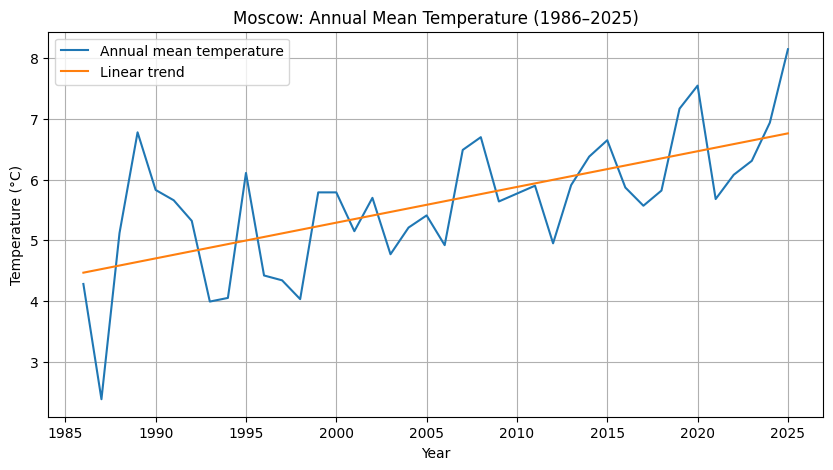

Estimated trend: 0.589 °C per decade


In [31]:

# Display all available locations
print("Available locations:")
print(", ".join(sorted(annual["city"].unique())))

# Choose a location
city = "Moscow"

# Keep only the selected city's data
city_data = annual[annual["city"] == city].sort_values("year")

# Calculate the linear trend
slope, intercept = np.polyfit(
    city_data["year"],
    city_data["annual_mean_temperature"],
    1
)

trend_line = slope * city_data["year"] + intercept

# Create the graph
plt.figure(figsize=(10, 5))

plt.plot(
    city_data["year"],
    city_data["annual_mean_temperature"],
    label="Annual mean temperature"
)

plt.plot(
    city_data["year"],
    trend_line,
    label="Linear trend"
)

plt.title(f"{city}: Annual Mean Temperature (1986–2025)")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Estimated trend: {slope * 10:.3f} °C per decade")


### Interpretation — Annual Temperature Trends

Looking at the graphs, I noticed that temperatures have generally increased in all ten locations between 1986 and 2025, but not at the same speed.

**Longyearbyen has the strongest estimated warming trend**, with +1.201°C per decade. This means its annual average temperature increased by around 1.2°C every ten years according to the trend line. Milan (+0.616°C) and Moscow (+0.589°C) also show relatively strong warming trends.

On the other hand, **Darwin has the weakest trend**, with only +0.027°C per decade. Its temperature changes from year to year, but the trend line is almost flat.

I also noticed that the annual temperatures do not increase continuously. Some years are warmer and others are colder, even when the overall trend is increasing. This is why I used a linear trend line to better understand the general direction over 40 years.

**My main observation:** All ten locations have positive estimated trends, but the warming is very different from one place to another. This shows why it is interesting to study several locations instead of looking at only one.

### **1.b Overview of Temperature Trends Across Climate Groups**

I wanted to group all ten locations into one figure to make the comparison easier. I organized them into five climate groups, with two locations in each group.

This allows me to see how temperatures have changed over 40 years and compare the warming trends of different locations, even within the same climate group.

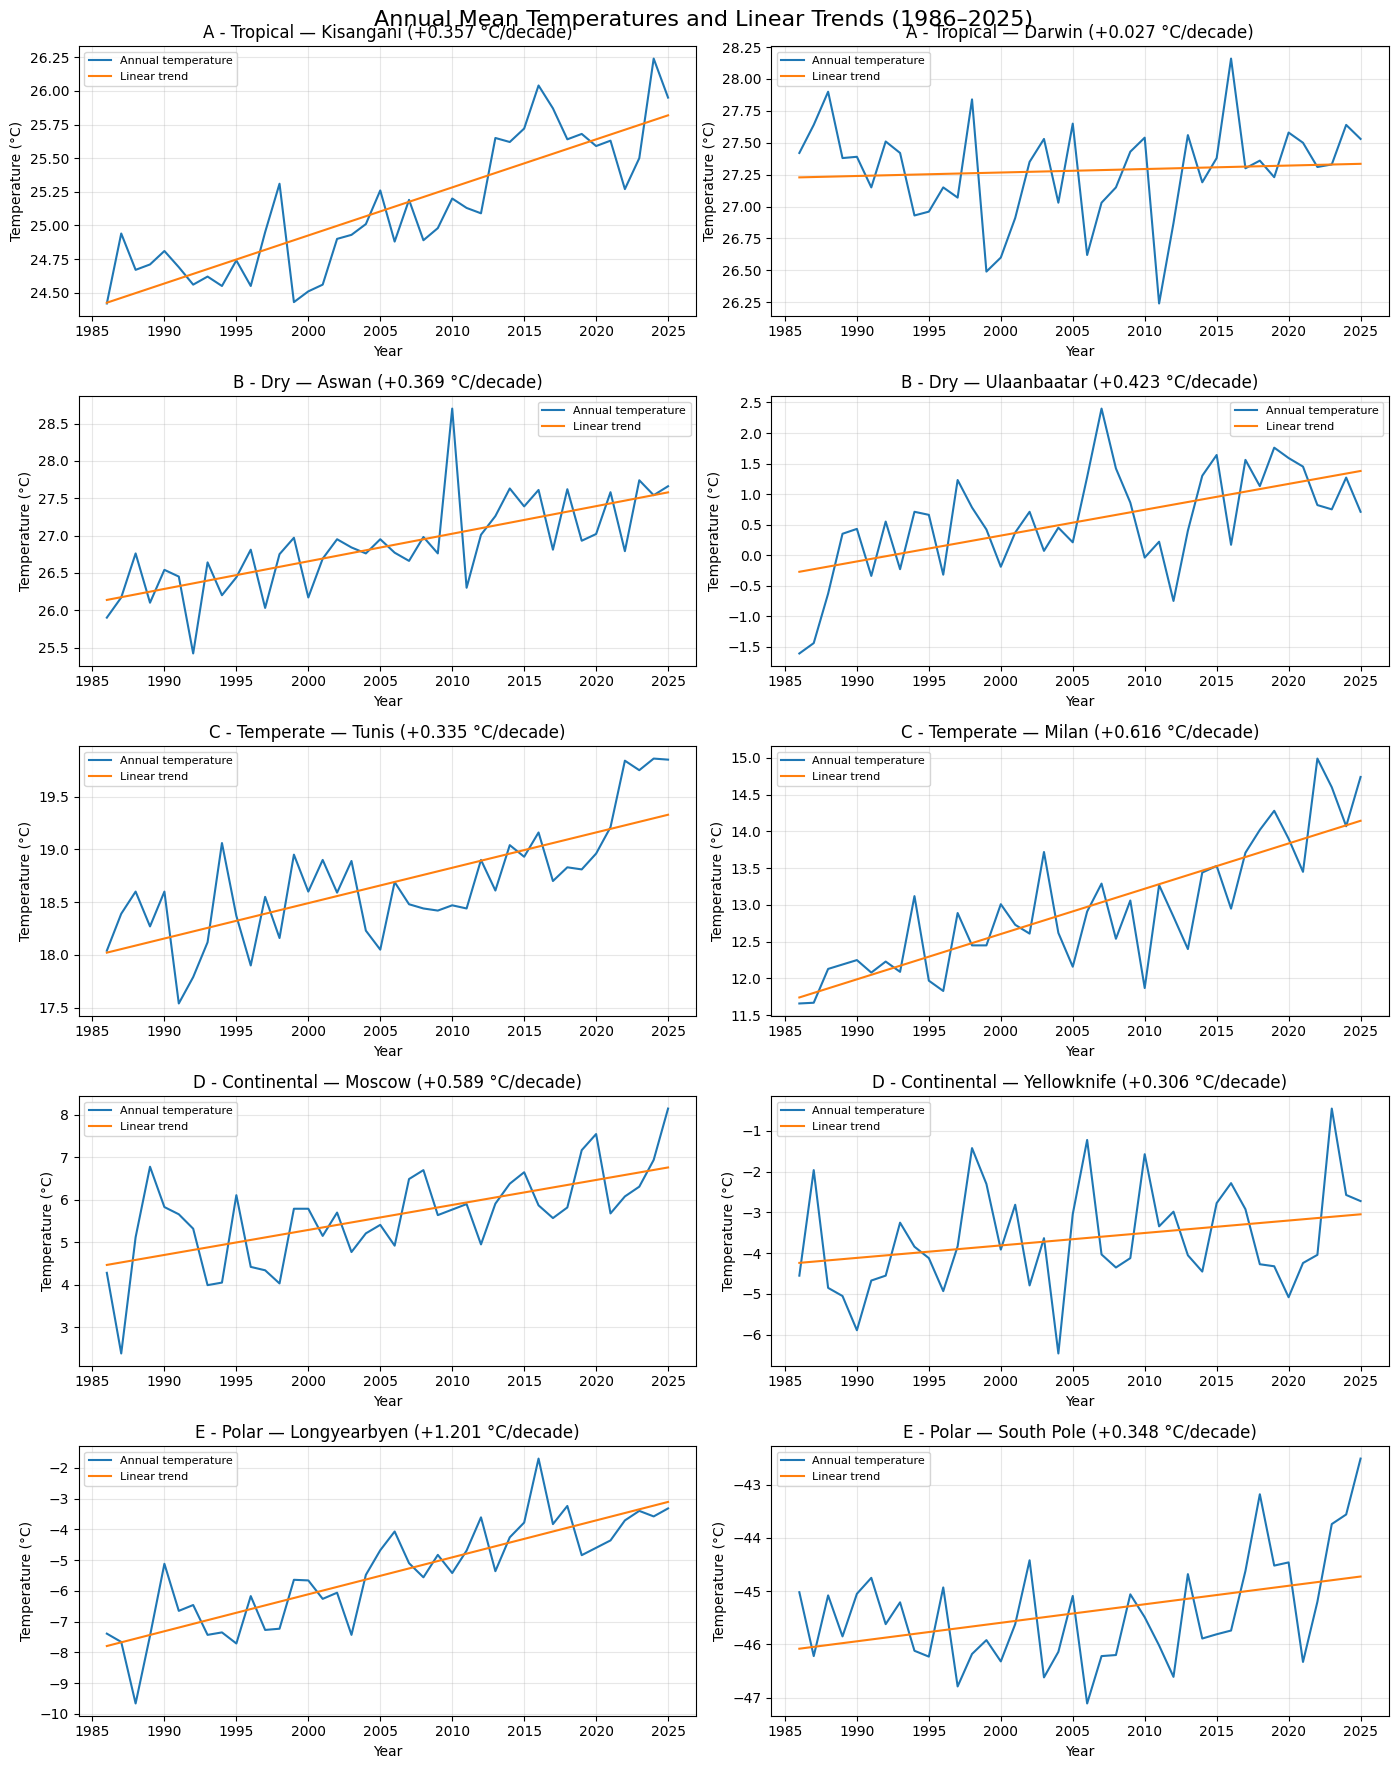

In [32]:

# Organize locations by climate group
climate_groups = {
    "A - Tropical": ["Kisangani", "Darwin"],
    "B - Dry": ["Aswan", "Ulaanbaatar"],
    "C - Temperate": ["Tunis", "Milan"],
    "D - Continental": ["Moscow", "Yellowknife"],
    "E - Polar": ["Longyearbyen", "South Pole"]
}

# Create 10 small graphs: 5 rows and 2 columns
fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for row, (group, cities) in enumerate(climate_groups.items()):
    for col, city in enumerate(cities):

        # Select the city's annual temperatures
        data = annual[annual["city"] == city].sort_values("year")

        # Calculate the linear regression
        slope, intercept = np.polyfit(
            data["year"],
            data["annual_mean_temperature"],
            1
        )

        # Get the correct subplot
        ax = axes[row, col]

        # Annual temperatures
        ax.plot(
            data["year"],
            data["annual_mean_temperature"],
            label="Annual temperature"
        )

        # Linear trend
        ax.plot(
            data["year"],
            slope * data["year"] + intercept,
            label="Linear trend"
        )

        ax.set_title(f"{group} — {city} ({slope * 10:+.3f} °C/decade)")
        ax.set_xlabel("Year")
        ax.set_ylabel("Temperature (°C)")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

fig.suptitle(
    "Annual Mean Temperatures and Linear Trends (1986–2025)",
    fontsize=16
)

plt.tight_layout()
plt.show()


### Interpretation — Temperature Trends Across Climate Groups

Looking at all ten graphs together, I noticed that the locations have very different average temperatures, but most importantly, their temperatures have not changed at the same speed over the 40 years.

One interesting example is **Group B (Dry)**. Aswan is generally much hotter than Ulaanbaatar, but Ulaanbaatar has a slightly higher warming trend (+0.423°C compared with +0.369°C per decade). This shows that a hotter location does not necessarily warm faster.

I also noticed a big difference in **Group E (Polar)**. Longyearbyen has the highest warming rate in the entire dataset (+1.201°C per decade), while the South Pole has a much lower trend (+0.348°C per decade), even though both belong to the polar climate group.

Another observation is that **Milan and Tunis (Group C)** have different warming rates despite belonging to the same broad climate group. Milan shows a stronger increase, while Tunis has a more moderate trend.

The blue lines also show that temperatures change from one year to another. Some locations have larger fluctuations, while others follow a more regular pattern.

**My main conclusion:** I learned that a location's average temperature and its warming rate are two different things. Also, belonging to the same climate group does not mean that two locations will experience the same temperature changes.

## **2. Annual Temperature Anomalies (1986–2025)**

In this section, I analyze annual temperature anomalies using the 1986–2005 period as a reference.

Instead of comparing absolute temperatures, anomalies show how much each year's temperature differs from its location's historical average.

This makes it easier to compare changes between locations with very different climates.

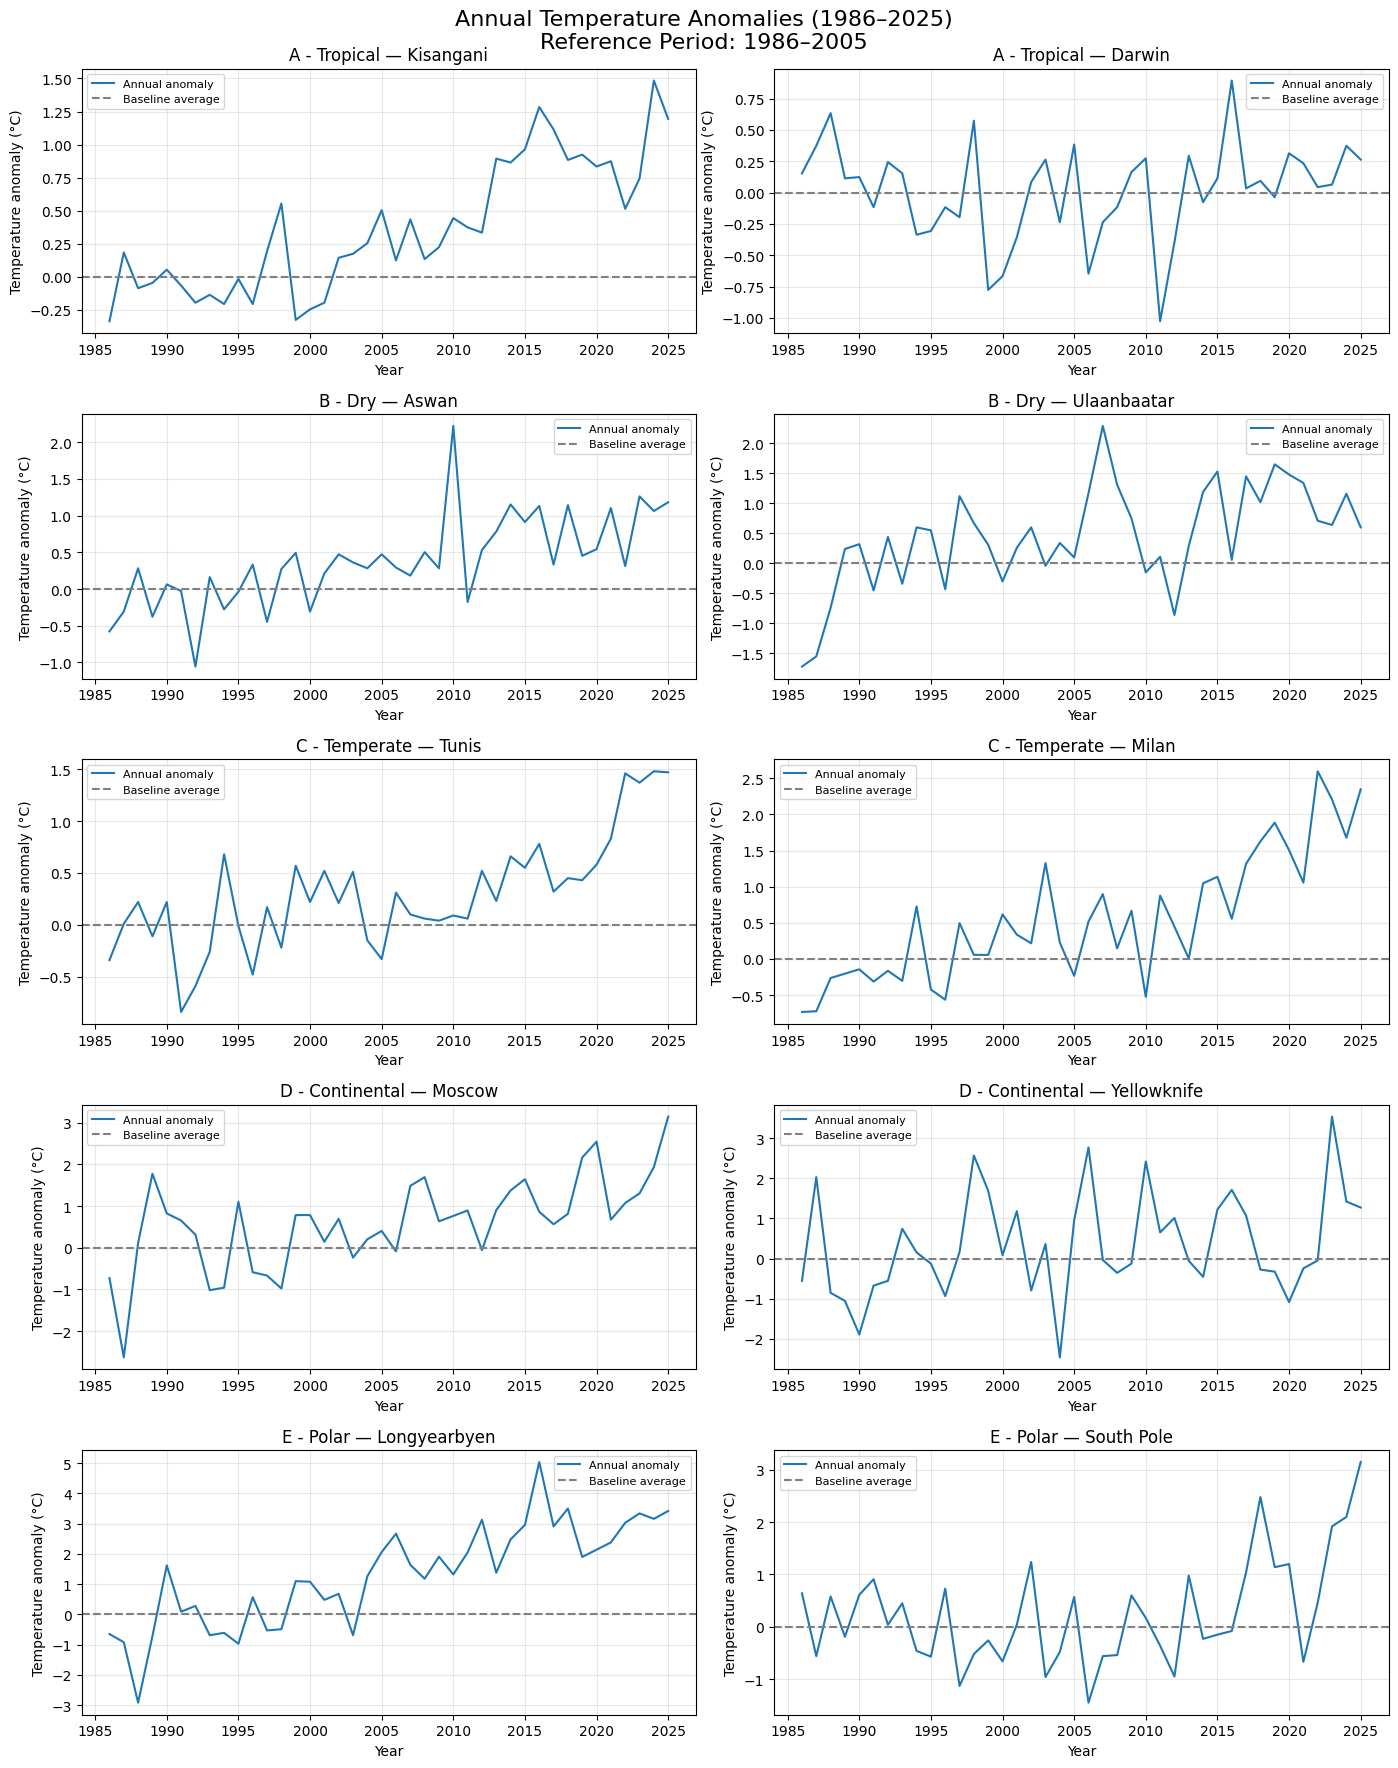

In [33]:

# Create 10 anomaly graphs (5 climate groups × 2 locations)
fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for row, (group, cities) in enumerate(climate_groups.items()):
    for col, city in enumerate(cities):

        # Select the city's anomaly data
        data = anomalies[
            anomalies["city"] == city
        ].sort_values("year")

        ax = axes[row, col]

        # Plot annual temperature anomalies
        ax.plot(
            data["year"],
            data["temperature_anomaly"],
            label="Annual anomaly"
        )

        # Reference line: zero anomaly
        ax.axhline(
            0,
            color="gray",
            linestyle="--",
            label="Baseline average"
        )

        ax.set_title(f"{group} — {city}")
        ax.set_xlabel("Year")
        ax.set_ylabel("Temperature anomaly (°C)")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

fig.suptitle(
    "Annual Temperature Anomalies (1986–2025)\n"
    "Reference Period: 1986–2005",
    fontsize=16
)

plt.tight_layout()
plt.show()


### Interpretation

Temperature anomalies allow me to compare changes across different climate conditions without focusing on the absolute temperature of each location.

The zero line represents the 1986–2005 average for each location. Positive values indicate warmer years, while negative values indicate colder years.

By examining these graphs, I can investigate whether positive anomalies become more frequent or larger toward the end of the study period.

### Important Observation

Looking at all ten graphs together, I noticed that locations within the same climate group can have different temperature patterns.

For example, Aswan and Ulaanbaatar both belong to Group B (Dry), but their average temperatures and year-to-year variations are very different.

I also noticed that some locations have larger annual fluctuations than others, even when their long-term warming trends are similar.

This shows why it is useful to compare both the annual temperature variations and the linear trends, rather than looking only at the warming rate.


## **3. Comparing Temperature Trends Within Climate Groups**

In this section, I compare the estimated warming rates of the two selected locations within each Köppen–Geiger climate group.

The warming rate is calculated using linear regression on annual mean temperatures between 1986 and 2025 and is expressed in °C per decade.

This comparison helps identify differences in temperature evolution between locations belonging to the same broad climate group.

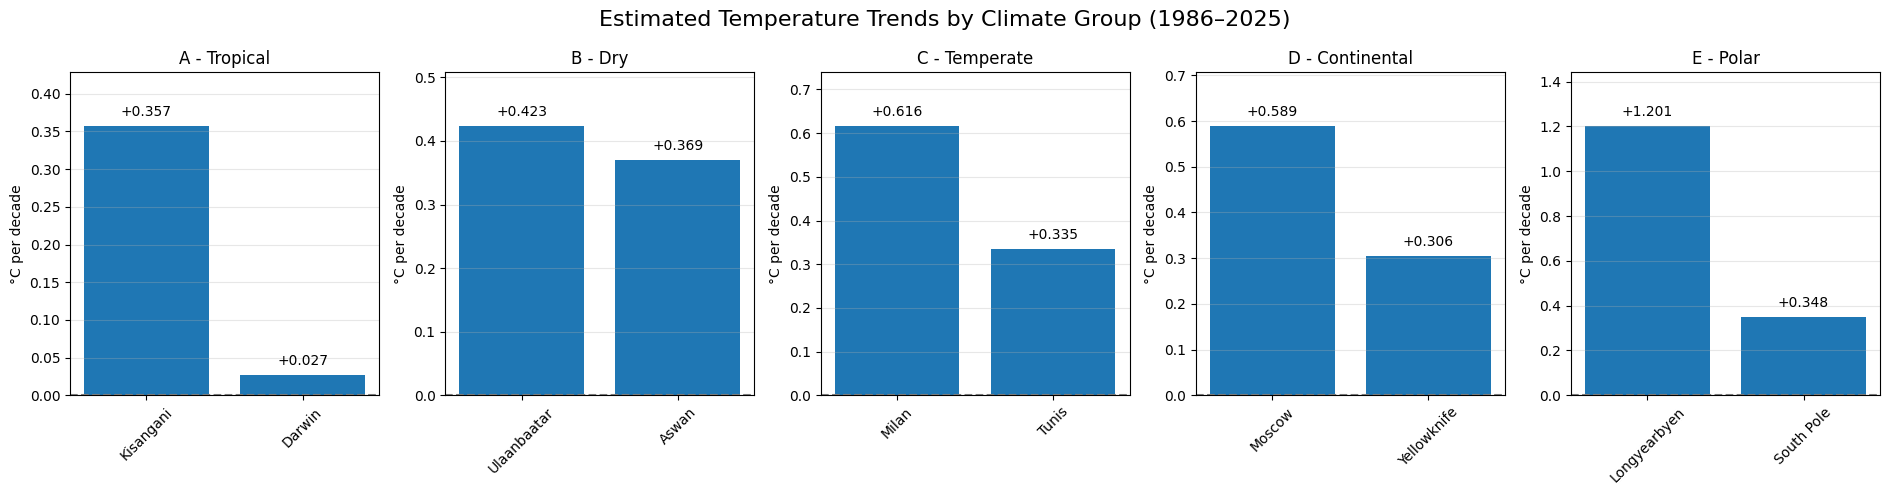

In [34]:

# Create five comparison graphs
fig, axes = plt.subplots(1, 5, figsize=(19, 5))

for i, (group, cities) in enumerate(climate_groups.items()):

    # Select the two locations in this group
    data = trends[trends["city"].isin(cities)]

    ax = axes[i]

    # Plot their estimated temperature trends
    bars = ax.bar(
        data["city"],
        data["trend_per_decade"]
    )

    # Show the exact values above the bars
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:+.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5 if height >= 0 else -5),
            textcoords="offset points",
            ha="center",
            va="bottom" if height >= 0 else "top"
        )

    ax.set_title(group)
    ax.set_ylabel("°C per decade")
    ax.tick_params(axis="x", rotation=45)
    ax.axhline(0, color="gray", linestyle="--")
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)

fig.suptitle(
    "Estimated Temperature Trends by Climate Group (1986–2025)",
    fontsize=16
)

plt.tight_layout()
plt.show()


### Interpretation — Climate Group Comparisons

Looking at the five graphs, I noticed that locations in the same climate group do not always have similar warming rates.

- Group A (Tropical): Kisangani (+0.357°C/decade) shows a much stronger warming trend than Darwin (+0.027°C/decade).
- Group B (Dry): Ulaanbaatar (+0.423°C/decade) has a slightly higher warming rate than Aswan (+0.369°C/decade). Their trends are relatively close.
- Group C (Temperate): Milan (+0.616°C/decade) shows almost twice the warming rate of Tunis (+0.335°C/decade).
- Group D (Continental): Moscow (+0.589°C/decade) has a higher warming rate than Yellowknife (+0.306°C/decade).
- Group E (Polar): Longyearbyen (+1.201°C/decade) shows a much stronger warming trend than the South Pole (+0.348°C/decade). This is the largest difference among our five pairs.

**My main observation:** Even when two locations belong to the same broad climate group, their temperature trends can be very different. This suggests that climate classification alone is not enough to explain how temperatures change in each location.

However, these results concern only the selected locations, not entire climate groups.

## **Additional Section: Humidity and Apparent Temperature**

In this section, I explore the relationship between air temperature, apparent temperature and relative humidity.

Apparent temperature represents how temperature feels under certain environmental conditions, rather than only the measured air temperature.

I calculate the difference between apparent temperature and air temperature for each annual observation.

The objective is to compare this difference across the selected locations and investigate whether it is associated with humidity.

In [35]:

# Create a copy of our annual dataset
weather = annual.copy()

# Calculate the difference between apparent and actual temperature
weather["temperature_difference"] = (
    weather["annual_apparent_temperature"] - weather["annual_mean_temperature"]
)

# Calculate averages for each location
humidity_summary = (
    weather.groupby("city")[
        ["annual_humidity", "temperature_difference"]
    ]
    .mean()
    .reset_index()
)

print("Average humidity and apparent temperature difference:")
print(humidity_summary.round(2).to_string(index=False))


Average humidity and apparent temperature difference:
        city  annual_humidity  temperature_difference
       Aswan            26.31                   -3.31
      Darwin            69.58                    3.26
   Kisangani            87.08                    4.82
Longyearbyen            82.27                   -4.18
       Milan            73.80                   -1.03
      Moscow            77.31                   -3.25
  South Pole            65.02                   -5.11
       Tunis            69.68                   -0.72
 Ulaanbaatar            59.66                   -3.72
 Yellowknife            73.24                   -4.25


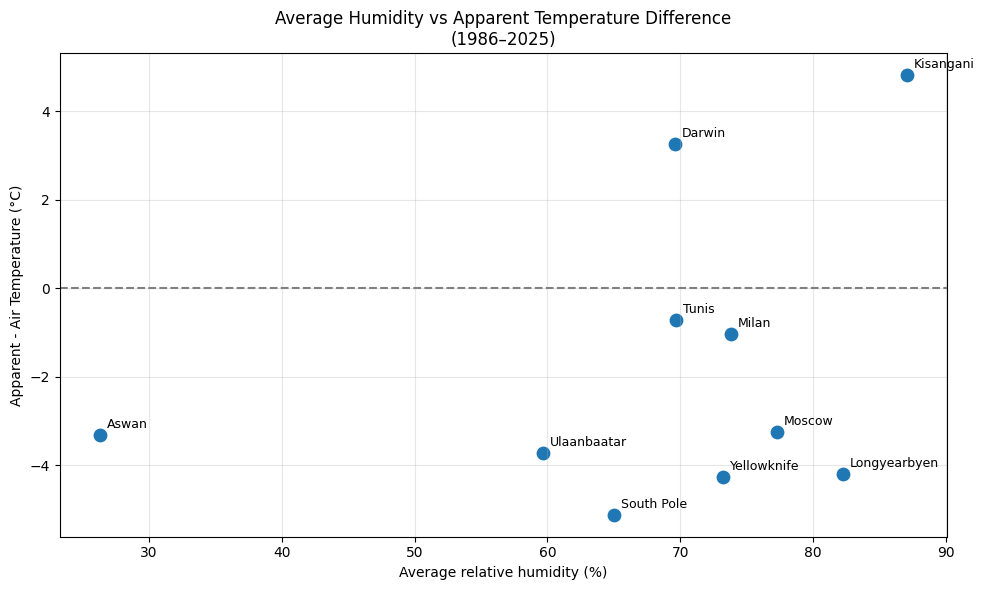

In [36]:

# Compare average humidity and temperature differences
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    humidity_summary["annual_humidity"],
    humidity_summary["temperature_difference"],
    s=80
)

# Label each location
for _, row in humidity_summary.iterrows():
    ax.annotate(
        row["city"],
        (
            row["annual_humidity"],
            row["temperature_difference"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# Reference line: apparent temperature equals air temperature
ax.axhline(0, color="gray", linestyle="--")

ax.set_title(
    "Average Humidity vs Apparent Temperature Difference\n"
    "(1986–2025)"
)
ax.set_xlabel("Average relative humidity (%)")
ax.set_ylabel("Apparent - Air Temperature (°C)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Interpretation

In this analysis, I explored how humidity relates to the difference between apparent temperature and actual air temperature.

For example, Kisangani has an average apparent temperature about 4.82°C higher than its measured air temperature, while Longyearbyen shows a difference of approximately −4.18°C.

These results show that the relationship varies between locations. Humidity is an important factor in thermal comfort, but this comparison does not measure its individual effect.

In future work, I would like to explore other variables, especially wind speed and air temperature, to better understand these differences.

### **Main Findings**

**1. Temperature trends**

The analysis shows positive estimated temperature trends across all ten selected locations between 1986 and 2025.

Longyearbyen has the strongest estimated warming trend, at approximately +1.201°C per decade, while Darwin shows the weakest, at approximately +0.027°C per decade.

**2. Temperature anomalies**

Annual temperature anomalies provide another way to examine temperature evolution by comparing individual years with the 1986–2005 reference period.

They allow changes to be compared between locations with very different average temperatures.

**3. Climate group comparisons**

Locations within the same broad Köppen–Geiger climate group do not necessarily experience similar warming rates.

For example, Milan has a higher estimated warming rate than Tunis, while Longyearbyen shows a much stronger trend than the South Pole.

**Humidity and apparent temperature**

The comparison of humidity and apparent temperature differences illustrates how perceived thermal conditions can vary between locations.

However, humidity alone cannot explain apparent temperature differences, since wind and other environmental factors also contribute.

### **Final Conclusion**

This project helped me explore how historical weather data can be collected, processed and analyzed using Python.

By combining annual temperature trends, temperature anomalies and comparisons across climate groups, I identified differences in how temperatures have evolved in the ten selected locations.

The results demonstrate that climate change patterns can vary considerably between geographical locations, even when those locations belong to the same broad climate category.

The analysis also highlights the importance of selecting appropriate reference periods, interpreting regression results carefully and recognizing the limitations of a small geographical sample.